# Assignment 3 - Differential privacy and synthetic data (California Housing)

Michail Pettas (mai25mps@cs.umu.se)

Where the tasks are in this notebook:
- Task 1 (scaling): section 2
- Task 2 (Laplace DP, 12 values of $\varepsilon$): section 4
- Task 3 (CTGAN trained on 5 different sample sizes): section 5
- Task 4 (utility, MSE and MAE): sections 3-5
- Task 5 ($\varepsilon$ that matches the synthetic data): section 6
- Task 6 (DP on the synthetic data): section 7

**Evaluation.** The data is split 80/20 once at the start. The test set is never noised, never given to
CTGAN and not used to fit the scaler. Every regressor is trained on some version of the training split
(original, DP, synthetic or DP on synthetic) and then scored on the real test set. This is usually called
"train on synthetic, test on real" (TSTR), and it shows how useful the released data is for predicting real
house values.

**Running time.** About 25 min on my laptop (CPU only), almost all of it for training the 15 CTGAN models.
The synthetic datasets are saved in `outputs/synthetic/`, so a re-run with `USE_CACHE = True` takes about a
minute. Package versions are in `requirements.txt`.

## 0. Setup

In [1]:
import time
import warnings
from pathlib import Path

# SDV/RDT/CTGAN and sklearn's Gaussian mixture (used inside CTGAN) emit many
# informational warnings, e.g. about the tiny 10-row training sets. They are
# expected here and would only clutter the output.
warnings.filterwarnings("ignore", module=r"(sdv|rdt|ctgan|sklearn\.mixture)")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import ticker
import torch
from IPython.display import display

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.neighbors import NearestNeighbors

from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer
from sdv.evaluation.single_table import evaluate_quality

In [2]:
# ---------------------------------------------------------------- experiment constants
SEED = 42                     # global seed: train/test split, regressors
TARGET = "MedHouseVal"        # median house value in units of $100,000
TEST_SIZE = 0.20

# Task 2: privacy budgets. epsilon is the total budget per record (all 9 attributes together).
EPSILONS = [0.1, 0.5, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 5000]
DP_REPEATS = 5                # independent noise draws per epsilon

# Task 3: number of ORIGINAL records CTGAN is trained on (the last one is the full training set)
SAMPLE_SIZES_SMALL = [10, 100, 1000, 5000]
CTGAN_SEEDS = [0, 1, 2]       # 3 independent (subsample, CTGAN init) runs per sample size
CTGAN_EPOCHS = 300            # SDV default

# Task 6: privacy budgets applied to the synthetic data (at least two are required)
DP_SYN_EPSILONS = [1, 10, 50, 100, 250, 500, 1000, 5000]

USE_CACHE = True              # reuse synthetic CSVs from a previous run when present

# ---------------------------------------------------------------- output folders
OUT = Path("outputs")
FIG_DIR, RES_DIR, SYN_DIR = OUT / "figures", OUT / "results", OUT / "synthetic"
for d in (FIG_DIR, RES_DIR, SYN_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- plotting
# same colour for the same kind of data in all figures
C_DP, C_SYN, C_DPSYN = "tab:blue", "tab:orange", "tab:green"   # DP / synthetic / DP on synthetic
C_REF, C_MUTED = "black", "grey"                                 # reference lines
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3, "legend.frameon": False})

np.random.seed(SEED)
torch.manual_seed(SEED)
print("torch threads:", torch.get_num_threads())

torch threads: 14


## 1. Data and train/test split

`fetch_california_housing` returns 20,640 districts (block groups from the 1990 census) with 8
numeric features and the target `MedHouseVal`. All columns are numeric and there are no missing
values.

In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
FEATURES = [c for c in df.columns if c != TARGET]
COLUMNS = FEATURES + [TARGET]          # all 9 attributes; DP noise is added to every one of them

print(df.shape, "| missing values:", int(df.isna().sum().sum()))
display(df.describe().T.round(3))

(20640, 9) | missing values: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


In [4]:
# One fixed split. The test part is real, untouched data used only for scoring.
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
N_TRAIN = len(train_df)
SAMPLE_SIZES = SAMPLE_SIZES_SMALL + [N_TRAIN]
print(f"train: {N_TRAIN} rows, test: {len(test_df)} rows")
print("CTGAN sample sizes:", SAMPLE_SIZES)

train: 16512 rows, test: 4128 rows
CTGAN sample sizes: [10, 100, 1000, 5000, 16512]


## 2. Pre-processing: clipping + Min-Max scaling (Task 1)

I use **Min-Max scaling to [0, 1]** instead of standardisation, mainly because of the Laplace mechanism in
Task 2. The noise has to be calibrated to the sensitivity, i.e. how much one person's record can change a
value. After Min-Max scaling every attribute lies in [0, 1], so every attribute has sensitivity 1 and the
same noise scale works for all of them. Z-scores have no fixed range, so the bounds would still have to
come from clipping, and the sensitivity would then be different for every attribute (clipped range divided
by the standard deviation).

Before scaling, each feature is clipped (winsorised) to its 1st-99th percentile. `AveRooms`, `AveBedrms`,
`Population` and `AveOccup` have very large outliers, e.g. `AveOccup` has a median of 2.8 but a maximum of
1243. With plain Min-Max almost all records end up in a tiny interval close to 0 (plot below), and noise
calibrated to the whole [0, 1] range would drown them. The target is already bounded (0.15 to 5.0), so it
is not clipped.

The bounds and the scaler are fitted on the training split only, and then reused for the test set and for
all synthetic data.

Note: for a strict DP guarantee the clipping bounds should not be computed from the private data. They
should come from domain knowledge, or be estimated with a small part of the privacy budget. Here I treat
the percentile bounds as public, which is a simplification.

In [5]:
# Clipping bounds (1st and 99th percentile) learned from the TRAINING split only
lower = train_df[FEATURES].quantile(0.01)
upper = train_df[FEATURES].quantile(0.99)
lower[TARGET], upper[TARGET] = train_df[TARGET].min(), train_df[TARGET].max()   # target: no clipping

def clip_to_bounds(d: pd.DataFrame) -> pd.DataFrame:
    # Winsorise every column to the training bounds.
    return d[COLUMNS].clip(lower=lower[COLUMNS], upper=upper[COLUMNS], axis=1)

scaler = MinMaxScaler().fit(clip_to_bounds(train_df))

def scale(d: pd.DataFrame) -> pd.DataFrame:
    # Winsorise and then Min-Max scale to [0, 1] with the scaler fitted on the training split.
    return pd.DataFrame(scaler.transform(clip_to_bounds(d)), columns=COLUMNS)

T_MIN, T_RANGE = scaler.data_min_[-1], scaler.data_range_[-1]   # target is the last column
def unscale_target(y_scaled):
    # Map a scaled prediction back to $100,000 units so MSE/MAE are in real units.
    return np.asarray(y_scaled) * T_RANGE + T_MIN

train_scaled = scale(train_df)
test_scaled = scale(test_df)

summary = pd.DataFrame({
    "raw min": train_df[COLUMNS].min(), "raw max": train_df[COLUMNS].max(),
    "clip low (p1)": lower[COLUMNS], "clip high (p99)": upper[COLUMNS],
    "% train values clipped": ((train_df[COLUMNS] < lower[COLUMNS]) | (train_df[COLUMNS] > upper[COLUMNS])).mean() * 100,
    "scaled min": train_scaled.min(), "scaled max": train_scaled.max(),
})
display(summary.round(3))

,raw min,raw max,clip low (p1),clip high (p99),% train values clipped,scaled min,scaled max
MedInc,0.500,15.000,1.067,10.577,2.011,0.0,1.0
HouseAge,1.000,52.000,4.000,52.000,0.612,0.0,1.0
AveRooms,0.889,141.909,2.578,10.318,2.011,0.0,1.0
AveBedrms,0.333,25.636,0.871,2.117,2.011,0.0,1.0
Population,3.000,35682.000,88.110,5798.720,2.011,0.0,1.0
AveOccup,0.692,1243.333,1.539,5.410,2.011,0.0,1.0
Latitude,32.550,41.950,32.680,40.649,1.896,0.0,1.0
Longitude,-124.350,-114.310,-123.239,-116.310,1.999,0.0,1.0
MedHouseVal,0.150,5.000,0.150,5.000,0.000,0.0,1.0


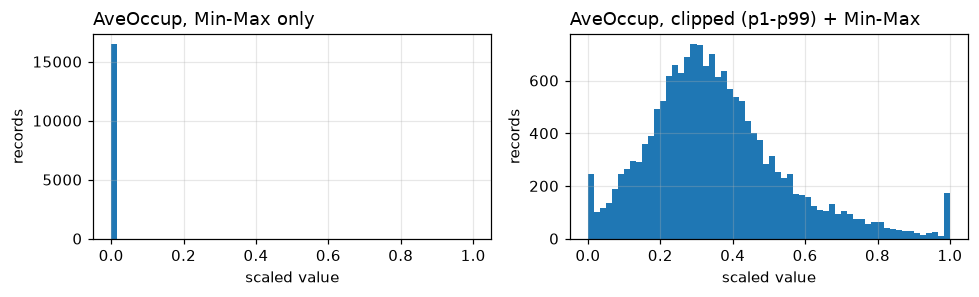

In [6]:
# Why clip before Min-Max: AveOccup scaled with and without clipping
raw_minmax = (train_df["AveOccup"] - train_df["AveOccup"].min()) / (train_df["AveOccup"].max() - train_df["AveOccup"].min())
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=False)
axes[0].hist(raw_minmax, bins=60, color=C_DP)
axes[0].set_title("AveOccup, Min-Max only", loc="left")
axes[1].hist(train_scaled["AveOccup"], bins=60, color=C_DP)
axes[1].set_title("AveOccup, clipped (p1-p99) + Min-Max", loc="left")
for ax in axes:
    ax.set_xlabel("scaled value"); ax.set_ylabel("records")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig0_scaling.png"); plt.show()

## 3. Utility measurement and choice of regressor (Task 4)

Utility is the error of a regressor that is trained on a (possibly privatised) training set and
evaluated on the **real** test set. Predictions are converted back to $100,000 units, so
**MSE is in ($100k)²** and **MAE is in $100k**.

Three standard regressors are compared on the original data to justify the choice:

In [7]:
X_test = test_scaled[FEATURES]
y_test = test_df[TARGET].to_numpy()          # real, unscaled target

def make_regressor(seed=SEED):
    # Histogram Gradient Boosting. Early stopping holds out 10 % of the given training data
    # (never the test set) and stops adding trees once the validation loss no longer improves.
    return HistGradientBoostingRegressor(early_stopping=True, validation_fraction=0.1,
                                         n_iter_no_change=10, random_state=seed)

def evaluate_utility(train_scaled_df: pd.DataFrame, seed=SEED, model=None) -> dict:
    # Train on a scaled training set (any variant) and score MSE/MAE on the real test set.
    model = make_regressor(seed) if model is None else model
    model.fit(train_scaled_df[FEATURES], train_scaled_df[TARGET])
    y_pred = unscale_target(model.predict(X_test))
    return {"MSE": mean_squared_error(y_test, y_pred), "MAE": mean_absolute_error(y_test, y_pred)}

# Compare candidate regressors on the original (scaled) training data.
# The first fit of the session is slow (thread pool start-up), so do one untimed fit first to get fair times.
make_regressor().fit(train_scaled[FEATURES], train_scaled[TARGET])
rows = []
for name, mdl in [("Linear regression", LinearRegression()),
                  ("Random forest (100 trees)", RandomForestRegressor(n_jobs=-1, random_state=SEED)),
                  ("Hist. gradient boosting", make_regressor())]:
    t0 = time.time()
    r = evaluate_utility(train_scaled, model=mdl)
    rows.append({"model": name, **r, "fit+predict time [s]": time.time() - t0})

# Reference: always predict the training mean. A model that is worse than this has learnt nothing useful.
mean_pred = np.full_like(y_test, train_df[TARGET].mean())
rows.append({"model": "Mean predictor (reference)", "MSE": mean_squared_error(y_test, mean_pred),
             "MAE": mean_absolute_error(y_test, mean_pred), "fit+predict time [s]": 0.0})
model_cmp = pd.DataFrame(rows).set_index("model")
model_cmp.to_csv(RES_DIR / "model_comparison.csv")
display(model_cmp.round(4))

,MSE,MAE,fit+predict time [s]
model,,,
Linear regression,0.4492,0.4882,0.0067
Random forest (100 trees),0.2570,0.3286,0.6680
Hist. gradient boosting,0.2166,0.3103,0.2256
Mean predictor (reference),1.3107,0.9061,0.0000


I chose **`HistGradientBoostingRegressor`**:
- It has the lowest error of the three. House value depends non-linearly on location (clusters around
  the coastal cities) and on income, which linear regression can't capture (about 2x the MSE).
- It has early stopping on an internal validation split. When the training data is mostly noise (small
  $\varepsilon$) it stops after a few iterations instead of fitting the noise.
- It is fast, about 0.2 s per fit, and the notebook fits more than 200 models. Random forest is slightly
  worse and 3-4 times slower.

Tree models are not affected by the scaling of the features, so the scaling in section 2 only matters for
the DP noise, not for the model.

The result on the original data below is the best utility we can expect, and everything else is compared
to it.

In [8]:
orig_runs = pd.DataFrame([evaluate_utility(train_scaled, seed=SEED + r) for r in range(DP_REPEATS)])
ORIG_MSE, ORIG_MAE = orig_runs["MSE"].mean(), orig_runs["MAE"].mean()
MEAN_MSE, MEAN_MAE = model_cmp.loc["Mean predictor (reference)", ["MSE", "MAE"]]
print(f"Original data   : MSE = {ORIG_MSE:.4f}  MAE = {ORIG_MAE:.4f}   (mean of {DP_REPEATS} regressor seeds)")
print(f"Mean predictor  : MSE = {MEAN_MSE:.4f}  MAE = {MEAN_MAE:.4f}")

Original data   : MSE = 0.2158  MAE = 0.3099   (mean of 5 regressor seeds)
Mean predictor  : MSE = 1.3107  MAE = 0.9061


In [9]:
# Check that the clipping from section 2 does not hurt accuracy:
# same regressor and seeds, but plain Min-Max scaling without clipping
plain = MinMaxScaler().fit(train_df[FEATURES])
X_train_plain = plain.transform(train_df[FEATURES])
X_test_plain = plain.transform(test_df[FEATURES])
noclip_mse = np.mean([mean_squared_error(y_test, make_regressor(SEED + r).fit(X_train_plain, train_df[TARGET]).predict(X_test_plain))
                      for r in range(DP_REPEATS)])
print(f"Original data, with clipping   : MSE = {ORIG_MSE:.4f}")
print(f"Original data, without clipping: MSE = {noclip_mse:.4f}")

Original data, with clipping   : MSE = 0.2158
Original data, without clipping: MSE = 0.2163


## 4. Differentially private dataset with the Laplace mechanism (Task 2)

Every scaled record $x \in [0,1]^d$ ($d = 9$, the 8 features and the target) gets independent Laplace noise
on every attribute:

$$\tilde{x}_j = x_j + Y_j, \qquad Y_j \sim \mathrm{Lap}(0,\ b), \qquad b = \frac{\Delta_1}{\varepsilon}$$

**Sensitivity.** Replacing one person's record changes each attribute by at most 1, since all of them are in
[0, 1]. So the L1 distance between two records is at most $\Delta_1 = 9$, which gives $b = 9/\varepsilon$.
By sequential composition this is the same as spending $\varepsilon/9$ on each attribute. Each record is
noised independently, so by parallel composition the whole dataset is $\varepsilon$-DP. It is actually
local DP, because every record is protected on its own.

Many examples simply add $\mathrm{Lap}(1/\varepsilon)$ to every attribute. That spends $\varepsilon$ per
attribute, so a record is only $9\varepsilon$-DP. An $\varepsilon$ in this notebook therefore corresponds
to $\varepsilon/9$ in that convention.

**Values of $\varepsilon$.** Local DP needs a large $\varepsilon$ before the data becomes useful, because
every single value is noised. The noise standard deviation is $\sqrt{2}\,b$, which is larger than the whole
[0, 1] range for every $\varepsilon < 12.7$. I therefore used a wide, log-spaced grid: 0.1-1 (strong
privacy), 10-500 (where the utility comes back) and 1000-5000 (almost no privacy).

The noisy values are not clipped back to [0, 1]. That would be allowed (post-processing), but with heavy
noise it pulls the mean of every attribute towards 0.5. The unclipped noise has mean zero, so averages
stay unbiased.

In [10]:
N_ATTR = len(COLUMNS)          # d = 9
SENSITIVITY_L1 = N_ATTR * 1.0  # each attribute is in [0, 1] -> range 1 per attribute

def laplace_mechanism(data_scaled: pd.DataFrame, epsilon: float, rng: np.random.Generator) -> pd.DataFrame:
    # epsilon-DP release of every record: add Lap(0, sensitivity/epsilon) noise to every attribute
    b = SENSITIVITY_L1 / epsilon
    noise = rng.laplace(loc=0.0, scale=b, size=data_scaled.shape)
    return data_scaled + noise

pd.DataFrame({"epsilon": EPSILONS,
              "Laplace scale b = 9/eps": [SENSITIVITY_L1 / e for e in EPSILONS],
              "noise std = sqrt(2)*b": [np.sqrt(2) * SENSITIVITY_L1 / e for e in EPSILONS],
              "eps per attribute (eps/9)": [e / N_ATTR for e in EPSILONS]}).round(4)

,epsilon,Laplace scale b = 9/eps,noise std = sqrt(2)*b,eps per attribute (eps/9)
0,0.1,90.0000,127.2792,0.0111
1,0.5,18.0000,25.4558,0.0556
2,1.0,9.0000,12.7279,0.1111
3,5.0,1.8000,2.5456,0.5556
4,10.0,0.9000,1.2728,1.1111
5,25.0,0.3600,0.5091,2.7778
6,50.0,0.1800,0.2546,5.5556
7,100.0,0.0900,0.1273,11.1111
8,250.0,0.0360,0.0509,27.7778
9,500.0,0.0180,0.0255,55.5556


In [11]:
# Generate the DP datasets: DP_REPEATS noise draws per epsilon, each one scored with the regressor
dp_rows, dp_examples = [], {}
t0 = time.time()
for eps in EPSILONS:
    for r in range(DP_REPEATS):
        rng = np.random.default_rng([SEED, r, int(eps * 1000)])   # different seed for every (eps, r)
        dp_train = laplace_mechanism(train_scaled, eps, rng)
        if r == 0:
            dp_examples[eps] = dp_train                            # keep one dataset per eps to look at
        dp_rows.append({"epsilon": eps, "repeat": r, **evaluate_utility(dp_train, seed=SEED + r)})
dp_results = pd.DataFrame(dp_rows)
dp_summary = dp_results.groupby("epsilon")[["MSE", "MAE"]].agg(["mean", "std"])
dp_results.to_csv(RES_DIR / "dp_runs.csv", index=False)
dp_summary.to_csv(RES_DIR / "dp_summary.csv")
print(f"{len(dp_results)} DP models in {time.time() - t0:.0f}s")
display(dp_summary.round(4))

60 DP models in 7s


MSE                MAE        
             mean       std     mean     std
epsilon                                     
0.1      218.2849  222.0755  12.3070  4.9509
0.5        3.5517    3.9455   1.4923  0.8858
1.0        3.4316    1.5136   1.5246  0.4234
5.0        1.4052    0.1728   0.9331  0.0970
10.0       1.2290    0.0898   0.8695  0.0415
25.0       0.9754    0.0271   0.7639  0.0142
50.0       0.6384    0.0072   0.6112  0.0076
100.0      0.4316    0.0058   0.4795  0.0032
250.0      0.3177    0.0062   0.3912  0.0043
500.0      0.2799    0.0019   0.3598  0.0014
1000.0     0.2527    0.0033   0.3389  0.0034
5000.0     0.2232    0.0016   0.3160  0.0019

In [12]:
# What the DP data looks like: first 3 records for a few values of epsilon (scaled)
preview = pd.concat({f"eps={e}": dp_examples[e].head(3) for e in [1, 100, 1000]} | {"original": train_scaled.head(3)})
display(preview.round(3))

MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
eps=1    0   3.292    12.979    -3.278     -3.393       7.639     0.538   
         1  -3.723    12.479    -2.543     26.967      41.503     7.685   
         2   2.270     6.823     5.605     10.380      -9.252    -8.486   
eps=100  0   0.353     0.685     0.337      0.087       0.435     0.274   
         1   0.174     1.083     0.196      0.283       0.218     0.084   
         2   0.768     0.005     0.322      0.066      -0.189     0.305   
eps=1000 0   0.237     0.600     0.308      0.117       0.417     0.567   
         1   0.283     0.943     0.257      0.111       0.199     0.075   
         2   0.319     0.001     0.372      0.098       0.147     0.312   
original 0   0.231     0.604     0.315      0.109       0.387     0.556   
         1   0.289     0.937     0.245      0.136       0.215     0.051   
         2   0.325     0.000     0.396      0.092       0.145     0.306   

            Latitude  Longitude  MedHouseVal  
eps=1    0    -7.179      2.445        8.728  
         1     6.033     15.547        6.121  
         2    -0.800     -6.165      -10.901  
eps=100  0    -0.006      0.847        0.158  
         1     0.174      0.809        0.803  
         2     0.328      0.305        0.328  
eps=1000 0     0.001      0.877        0.170  
         1     0.103      0.742        0.732  
         2     0.257      0.402        0.330  
original 0     0.004      0.896        0.181  
         1     0.137      0.733        0.757  
         2     0.248      0.398        0.325

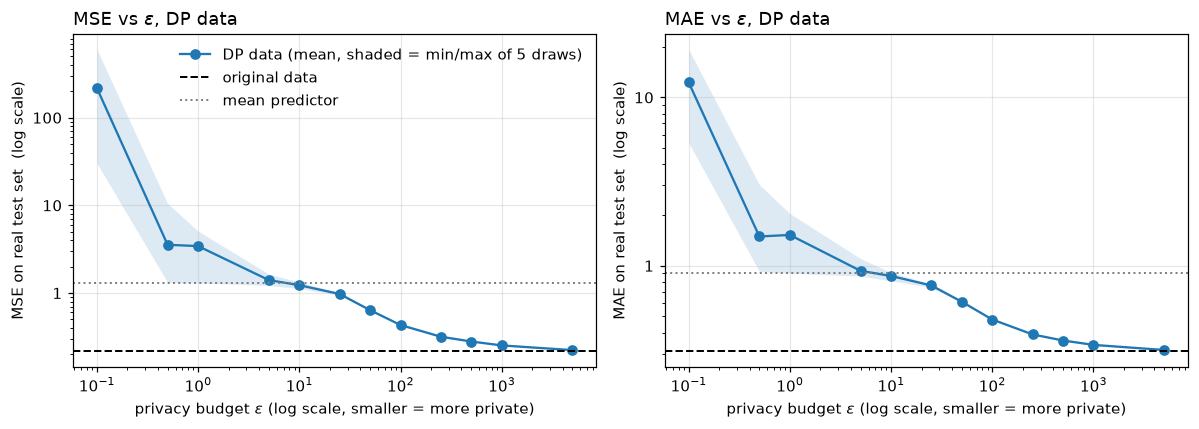

In [13]:
# Figure 1: utility of the DP datasets (MSE vs epsilon), plus MAE
def plot_vs_x(ax, runs, xcol, metric, color, label, marker="o"):
    # mean over runs as a line, shaded area = min to max over runs
    # (mean +- std goes below zero for small eps, which doesn't work on a log axis)
    g = runs.groupby(xcol)[metric]
    x = g.mean().index.to_numpy(dtype=float)
    ax.fill_between(x, g.min().to_numpy(), g.max().to_numpy(), color=color, alpha=0.15, lw=0)
    ax.plot(x, g.mean().to_numpy(), marker=marker, color=color, label=label)

def plain_log_ticks(ax, minor=False):
    # show plain numbers (0.3, 1, 10) on a log y-axis instead of 10^x notation
    fmt = ticker.FuncFormatter(lambda v, _: f"{v:g}")
    ax.yaxis.set_major_formatter(fmt)
    if minor:   # for short ranges also label 2, 3 and 5
        ax.yaxis.set_minor_locator(ticker.LogLocator(subs=[2, 3, 5]))
        ax.yaxis.set_minor_formatter(fmt)
    else:
        ax.yaxis.set_minor_formatter(ticker.NullFormatter())

def reference_lines(ax, metric):
    ref = {"MSE": (ORIG_MSE, MEAN_MSE), "MAE": (ORIG_MAE, MEAN_MAE)}[metric]
    ax.axhline(ref[0], color=C_REF, ls="--", lw=1.3, label="original data")
    ax.axhline(ref[1], color=C_MUTED, ls=":", lw=1.3, label="mean predictor")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MSE", "MAE"]):
    plot_vs_x(ax, dp_results, "epsilon", metric, C_DP, f"DP data (mean, shaded = min/max of {DP_REPEATS} draws)")
    reference_lines(ax, metric)
    ax.set_xscale("log"); ax.set_yscale("log"); plain_log_ticks(ax)
    ax.set_xlabel(r"privacy budget $\epsilon$ (log scale, smaller = more private)")
    ax.set_ylabel(f"{metric} on real test set  (log scale)")
    ax.set_title(rf"{metric} vs $\epsilon$, DP data", loc="left")
axes[0].legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_dp_utility.png"); plt.show()

## 5. Synthetic data with CTGAN (Tasks 3 and 4)

**Synthesizer.** I use SDV's `CTGANSynthesizer`. CTGAN (Xu et al., 2019) is a GAN made for tabular data.
Two things make it a good fit here:
- Mode-specific normalisation: each continuous column is modelled with a Gaussian mixture, so skewed or
  multi-modal columns like `Population`, `AveOccup` and latitude/longitude (two big city clusters) are
  handled better than with a single Gaussian.
- The generator learns the joint distribution, so it can keep the feature-target relations that the
  regressor needs, not only the distribution of each column.

`GaussianCopulaSynthesizer` would be much faster but only captures correlations, and `TVAESynthesizer`
often gives similar results. I used CTGAN since the assignment suggests it.

**Setup.**
- CTGAN is trained on the raw (unscaled) training records because it normalises the data itself. The
  output is then clipped and scaled with the same bounds and scaler as the real data.
- Sample sizes n = 10, 100, 1000, 5000 and 16512 (the whole training set). Each n is run 3 times with a
  different random subsample and seed, since GAN training varies a lot between runs.
- Every model generates 16512 rows (same size as the real training set), so the only difference between
  the datasets is how much real data CTGAN saw.
- SDV defaults are used (300 epochs, batch size 500). With a fixed number of epochs, a model trained on
  10 records gets far fewer gradient steps than one trained on 16512, which should be kept in mind.
- SDV detects `Latitude`/`Longitude` as PII and would replace them with random coordinates in the output.
  Location is the most important predictor of house value, so I set both columns back to `numerical`.

In [14]:
metadata = Metadata.detect_from_dataframe(train_df, table_name="housing")
print("auto-detected:", {c: metadata.to_dict()["tables"]["housing"]["columns"][c] for c in ["Latitude", "Longitude"]})
for col in ["Latitude", "Longitude"]:
    metadata.update_column(column_name=col, sdtype="numerical", table_name="housing")
metadata.validate()
print("after fix    :", {c: metadata.to_dict()["tables"]["housing"]["columns"][c] for c in ["Latitude", "Longitude"]})

auto-detected: {'Latitude': {'pii': True, 'sdtype': 'latitude'}, 'Longitude': {'pii': True, 'sdtype': 'longitude'}}
after fix    : {'Latitude': {'sdtype': 'numerical'}, 'Longitude': {'sdtype': 'numerical'}}


In [15]:
def get_synthetic(n: int, seed: int) -> tuple[pd.DataFrame, pd.DataFrame, float]:
    # Return (synthetic data, the original subsample CTGAN was trained on, fit time in s).
    # The subsample is drawn deterministically from (n, seed), so it can be rebuilt when the
    # synthetic data comes from the cache.
    subset = train_df if n >= N_TRAIN else train_df.sample(n=n, random_state=seed)
    path = SYN_DIR / f"ctgan_n{n}_seed{seed}.csv"
    time_path = path.with_suffix(".fit_time.txt")               # fit time of the cached model
    if USE_CACHE and path.exists():
        fit_time = float(time_path.read_text()) if time_path.exists() else float("nan")
        return pd.read_csv(path), subset, fit_time
    torch.manual_seed(seed); np.random.seed(seed)             # reproducible GAN initialisation
    synth = CTGANSynthesizer(metadata, epochs=CTGAN_EPOCHS, verbose=False)
    t0 = time.time()
    synth.fit(subset)
    fit_time = time.time() - t0
    synthetic = synth.sample(num_rows=N_TRAIN)
    synthetic.to_csv(path, index=False)
    time_path.write_text(f"{fit_time:.1f}")
    return synthetic, subset, fit_time

def dcr_stats(synth_scaled: pd.DataFrame, source_scaled: pd.DataFrame) -> dict:
    # Privacy check with Distance to Closest Record (DCR).
    # How close are the synthetic rows to the records CTGAN was trained on, compared to how close
    # new real rows (the test set) are to the same records? A ratio well below 1 would mean that
    # CTGAN copies / memorises its training records.
    nn = NearestNeighbors(n_neighbors=1).fit(source_scaled[COLUMNS])
    d_syn = nn.kneighbors(synth_scaled[COLUMNS])[0].ravel()
    d_hold = nn.kneighbors(test_scaled[COLUMNS])[0].ravel()
    return {"DCR synth (median)": np.median(d_syn), "DCR holdout (median)": np.median(d_hold),
            "DCR ratio": np.median(d_syn) / np.median(d_hold), "exact copies [%]": (d_syn < 1e-6).mean() * 100}

In [16]:
syn_rows, synthetic_sets = [], {}
t_all = time.time()
for n in SAMPLE_SIZES:
    for seed in CTGAN_SEEDS:
        synthetic, subset, fit_time = get_synthetic(n, seed)
        synthetic_sets[(n, seed)] = synthetic
        syn_scaled = scale(synthetic)
        quality = evaluate_quality(train_df, synthetic, metadata, verbose=False).get_score()   # SDV fidelity score in [0,1]
        syn_rows.append({"n_samples": n, "seed": seed, **evaluate_utility(syn_scaled, seed=SEED + seed),
                         "SDV quality": quality, **dcr_stats(syn_scaled, scale(subset)), "fit time [s]": fit_time})
        print(f"n={n:>6} seed={seed}  MSE={syn_rows[-1]['MSE']:.4f}  quality={quality:.3f}  "
              f"fit={fit_time:.0f}s  (elapsed {time.time() - t_all:.0f}s)")
syn_results = pd.DataFrame(syn_rows)
syn_summary = syn_results.groupby("n_samples")[["MSE", "MAE", "SDV quality", "DCR ratio", "exact copies [%]"]].agg(["mean", "std"])
syn_results.to_csv(RES_DIR / "synthetic_runs.csv", index=False)
syn_summary.to_csv(RES_DIR / "synthetic_summary.csv")
display(syn_summary.round(4))

n=    10 seed=0  MSE=1.1915  quality=0.668  fit=7s  (elapsed 0s)


n=    10 seed=1  MSE=1.7695  quality=0.678  fit=6s  (elapsed 1s)


n=    10 seed=2  MSE=1.4454  quality=0.639  fit=6s  (elapsed 1s)


n=   100 seed=0  MSE=1.3173  quality=0.668  fit=6s  (elapsed 1s)


n=   100 seed=1  MSE=2.0062  quality=0.685  fit=6s  (elapsed 2s)


...

n=  5000 seed=2  MSE=1.2342  quality=0.762  fit=122s  (elapsed 6s)


n= 16512 seed=0  MSE=0.7648  quality=0.857  fit=252s  (elapsed 7s)


n= 16512 seed=1  MSE=0.7672  quality=0.862  fit=278s  (elapsed 8s)


n= 16512 seed=2  MSE=0.7689  quality=0.871  fit=250s  (elapsed 9s)


MSE             MAE         SDV quality         DCR ratio  \
             mean     std    mean     std        mean     std      mean   
n_samples                                                                 
10         1.4688  0.2897  0.9365  0.0809      0.6616  0.0205    1.0849   
100        1.8356  0.4575  1.0755  0.2113      0.6660  0.0195    1.9141   
1000       1.7080  0.4141  0.9485  0.0870      0.6824  0.0150    2.2955   
5000       1.2598  0.0236  0.8762  0.0269      0.7605  0.0089    2.0895   
16512      0.7670  0.0021  0.6780  0.0096      0.8633  0.0070    1.4952   

                  exact copies [%]       
              std             mean  std  
n_samples                                
10         0.0766              0.0  0.0  
100        0.0793              0.0  0.0  
1000       0.2364              0.0  0.0  
5000       0.0617              0.0  0.0  
16512      0.0511              0.0  0.0

In [17]:
# Sanity check: marginals of the best synthetic dataset vs the real training data
display(pd.concat({"real": train_df.describe().T[["mean", "std", "min", "max"]],
                   f"CTGAN n={N_TRAIN}": synthetic_sets[(N_TRAIN, 0)].describe().T[["mean", "std", "min", "max"]]}, axis=1).round(3))

real                               CTGAN n=16512            \
                 mean       std      min        max          mean       std   
MedInc          3.881     1.904    0.500     15.000         3.988     1.988   
HouseAge       28.608    12.602    1.000     52.000        30.734    12.582   
AveRooms        5.435     2.387    0.889    141.909         5.511     1.745   
AveBedrms       1.097     0.433    0.333     25.636         1.100     0.185   
Population   1426.453  1137.056    3.000  35682.000      1734.508  1347.057   
AveOccup        3.097    11.579    0.692   1243.333         3.223     0.781   
Latitude       35.643     2.137   32.550     41.950        35.444     1.913   
Longitude    -119.582     2.006 -124.350   -114.310      -119.502     1.965   
MedHouseVal     2.072     1.156    0.150      5.000         2.186     1.303   

                                 
                 min        max  
MedInc         0.936     15.000  
HouseAge       2.000     52.000  
AveRooms       1.031     32.973  
AveBedrms      0.731      3.071  
Population    66.000  11232.000  
AveOccup       1.461      7.598  
Latitude      32.550     41.350  
Longitude   -124.350   -114.710  
MedHouseVal    0.358      5.000

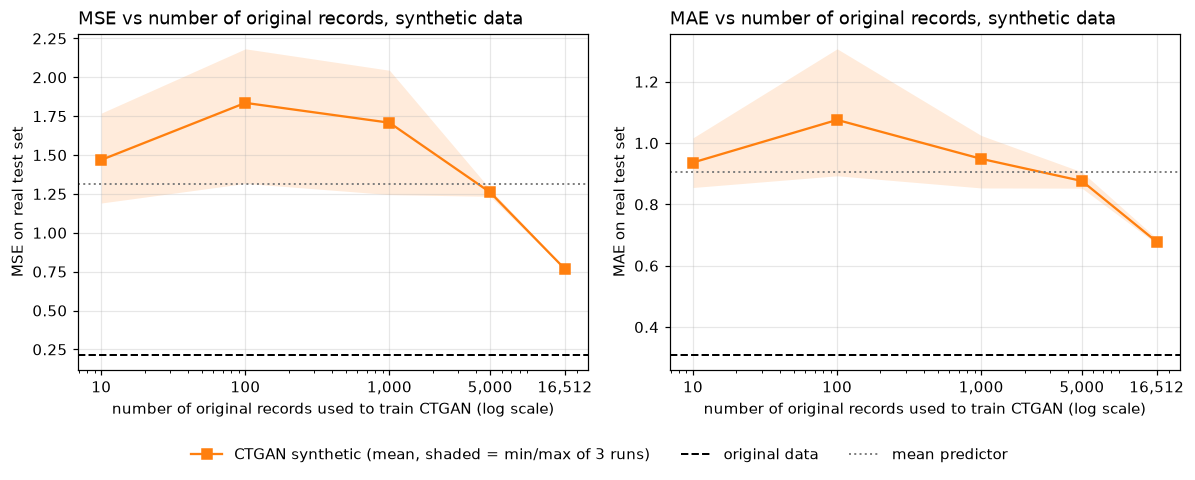

In [18]:
# Figure 2: utility of the synthetic datasets (MSE vs number of original samples)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MSE", "MAE"]):
    plot_vs_x(ax, syn_results, "n_samples", metric, C_SYN, f"CTGAN synthetic (mean, shaded = min/max of {len(CTGAN_SEEDS)} runs)", marker="s")
    reference_lines(ax, metric)
    ax.set_xscale("log")
    ax.set_xticks(SAMPLE_SIZES, [f"{n:,}" for n in SAMPLE_SIZES])
    ax.set_xlabel("number of original records used to train CTGAN (log scale)")
    ax.set_ylabel(f"{metric} on real test set")
    ax.set_title(f"{metric} vs number of original records, synthetic data", loc="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_synthetic_utility.png"); plt.show()

## 6. Which $\varepsilon$ gives the same utility as a synthetic dataset? (Task 5)

I interpolate the mean DP curve (MSE against $\log_{10}\varepsilon$) to find the $\varepsilon^*$ where the
DP data has the same MSE as each synthetic dataset. The curve is first made non-increasing with a running
minimum. To check the result, new DP datasets are generated at each $\varepsilon^*$ and scored.

In [19]:
eps_grid = dp_summary.index.to_numpy(dtype=float)
mse_curve = np.minimum.accumulate(dp_summary[("MSE", "mean")].to_numpy())   # enforce non-increasing

def matching_epsilon(target_mse: float) -> float:
    # epsilon where the interpolated DP MSE curve is equal to target_mse
    if target_mse >= mse_curve[0]:
        return eps_grid[0]            # synthetic data is not better than DP at the smallest eps
    if target_mse <= mse_curve[-1]:
        return np.inf                 # better than DP for every eps in the grid
    # np.interp needs increasing x values, so reverse the (decreasing) MSE curve
    return 10 ** np.interp(target_mse, mse_curve[::-1], np.log10(eps_grid)[::-1])

match_rows = []
for n in SAMPLE_SIZES:
    syn_mse = syn_summary.loc[n, ("MSE", "mean")]
    eps_star = matching_epsilon(syn_mse)
    # check: make new DP datasets at eps* and score them
    check = [evaluate_utility(laplace_mechanism(train_scaled, eps_star, np.random.default_rng([SEED, 99, r])), seed=SEED + r)["MSE"]
             for r in range(DP_REPEATS)] if np.isfinite(eps_star) else [np.nan]
    match_rows.append({"n_samples": n, "synthetic MSE": syn_mse, "matching eps*": eps_star,
                       "eps*/9 (per attribute)": eps_star / N_ATTR,
                       "DP MSE at eps* (mean)": np.mean(check), "DP MSE at eps* (std)": np.std(check)})
match_df = pd.DataFrame(match_rows).set_index("n_samples")
match_df.to_csv(RES_DIR / "eps_matching.csv")
display(match_df.round(4))

,synthetic MSE,matching eps*,eps*/9 (per attribute),DP MSE at eps* (mean),DP MSE at eps* (std)
n_samples,,,,,
10,1.4688,4.7539,0.5282,1.5601,0.2781
100,1.8356,3.5525,0.3947,1.3956,0.1001
1000,1.7080,3.9314,0.4368,1.4190,0.0579
5000,1.2598,8.8586,0.9843,1.2908,0.0309
16512,0.7670,38.3821,4.2647,0.7800,0.0168


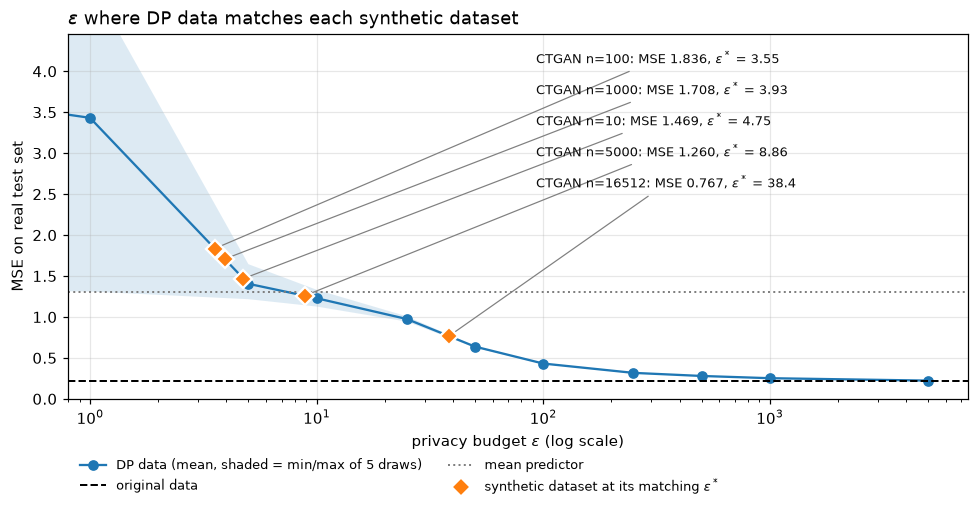

In [20]:
# Figure 3: each synthetic dataset drawn on the DP curve at its matching eps*.
# Linear y-axis, zoomed to eps >= 1. Some points are very close to each other, so the labels are
# put in a column in the upper right with lines to the points (sorted by MSE so the lines don't cross).
fig, ax = plt.subplots(figsize=(9, 4.8))
plot_vs_x(ax, dp_results, "epsilon", "MSE", C_DP, f"DP data (mean, shaded = min/max of {DP_REPEATS} draws)")
reference_lines(ax, "MSE")
ax.set_xscale("log")
ax.set_xlim(0.8, eps_grid[-1] * 1.5)
ax.set_ylim(0, 1.3 * max(MEAN_MSE, match_df["synthetic MSE"].max(), dp_summary.loc[1, ("MSE", "mean")]))
finite = match_df[np.isfinite(match_df["matching eps*"])].sort_values("synthetic MSE", ascending=False)
for k, (n, row) in enumerate(finite.iterrows()):
    xy = (row["matching eps*"], row["synthetic MSE"])
    ax.plot(*xy, "D", color=C_SYN, ms=8, mec="white", mew=1.5, zorder=5)
    ax.annotate(rf"CTGAN n={n}: MSE {row['synthetic MSE']:.3f}, $\epsilon^*$ = {row['matching eps*']:.3g}", xy,
                xytext=(0.52, 0.93 - 0.085 * k), textcoords="axes fraction", ha="left", va="center",
                fontsize=8.5, color="#0b0b0b",
                arrowprops=dict(arrowstyle="-", color=C_MUTED, lw=0.8, shrinkA=2, shrinkB=5))
ax.plot([], [], "D", color=C_SYN, ms=8, mec="white", label=r"synthetic dataset at its matching $\epsilon^*$")
ax.set_xlabel(r"privacy budget $\epsilon$ (log scale)"); ax.set_ylabel("MSE on real test set")
ax.set_title(r"$\epsilon$ where DP data matches each synthetic dataset", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.13), ncol=2, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_comparison.png"); plt.show()

## 7. Differential privacy applied to synthetic data (Task 6)

The three synthetic datasets trained on all 16512 records (the best ones) are scaled and then passed
through the same Laplace mechanism as in section 4, for 8 values of $\varepsilon$ with 5 noise draws each.
The regressor is again scored on the real test set.

Note: this makes the release $\varepsilon$-DP with respect to the *synthetic* records only. CTGAN itself
is not trained with DP, so it can still leak information about the real records, and adding noise
afterwards does not fix that. For a real guarantee the synthesizer has to be trained with DP (e.g.
DP-CTGAN / PATE-CTGAN in SmartNoise, or CTGAN with DP-SGD via Opacus). Its output is then DP by
post-processing and needs no extra noise.

In [21]:
dpsyn_rows = []
t0 = time.time()
for seed in CTGAN_SEEDS:
    syn_scaled = scale(synthetic_sets[(N_TRAIN, seed)])
    for eps in DP_SYN_EPSILONS:
        for r in range(DP_REPEATS):
            rng = np.random.default_rng([SEED, 7, seed, r, int(eps * 1000)])
            dp_syn = laplace_mechanism(syn_scaled, eps, rng)
            dpsyn_rows.append({"epsilon": eps, "ctgan_seed": seed, "repeat": r,
                               **evaluate_utility(dp_syn, seed=SEED + r)})
dpsyn_results = pd.DataFrame(dpsyn_rows)
dpsyn_summary = dpsyn_results.groupby("epsilon")[["MSE", "MAE"]].agg(["mean", "std"])
SYN_FULL_MSE = syn_summary.loc[N_TRAIN, ("MSE", "mean")]
SYN_FULL_MAE = syn_summary.loc[N_TRAIN, ("MAE", "mean")]
# Utility loss compared to the same synthetic data without noise, and DP on the original data for comparison
degr = pd.DataFrame({
    "DP-synthetic MSE": dpsyn_summary[("MSE", "mean")],
    "MSE increase vs synthetic [%]": (dpsyn_summary[("MSE", "mean")] / SYN_FULL_MSE - 1) * 100,
    "DP-original MSE (same eps)": dp_summary[("MSE", "mean")].reindex(DP_SYN_EPSILONS),
    "DP-synthetic MAE": dpsyn_summary[("MAE", "mean")],
})
dpsyn_results.to_csv(RES_DIR / "dp_synthetic_runs.csv", index=False)
dpsyn_summary.to_csv(RES_DIR / "dp_synthetic_summary.csv")
degr.to_csv(RES_DIR / "dp_synthetic_degradation.csv")
print(f"{len(dpsyn_results)} DP-synthetic models in {time.time() - t0:.0f}s;  synthetic (no noise) MSE = {SYN_FULL_MSE:.4f}")
display(degr.round(4))

120 DP-synthetic models in 14s;  synthetic (no noise) MSE = 0.7670


,DP-synthetic MSE,MSE increase vs synthetic [%],DP-original MSE (same eps),DP-synthetic MAE
epsilon,,,,
1,2.0286,164.4965,3.4316,1.1098
10,1.2574,63.9419,1.2290,0.8923
50,0.9403,22.6010,0.6384,0.7794
100,0.8141,6.1473,0.4316,0.7209
250,0.7525,-1.8903,0.3177,0.6818
500,0.7453,-2.8269,0.2799,0.6725
1000,0.7562,-1.3994,0.2527,0.6758
5000,0.7641,-0.3712,0.2232,0.6772


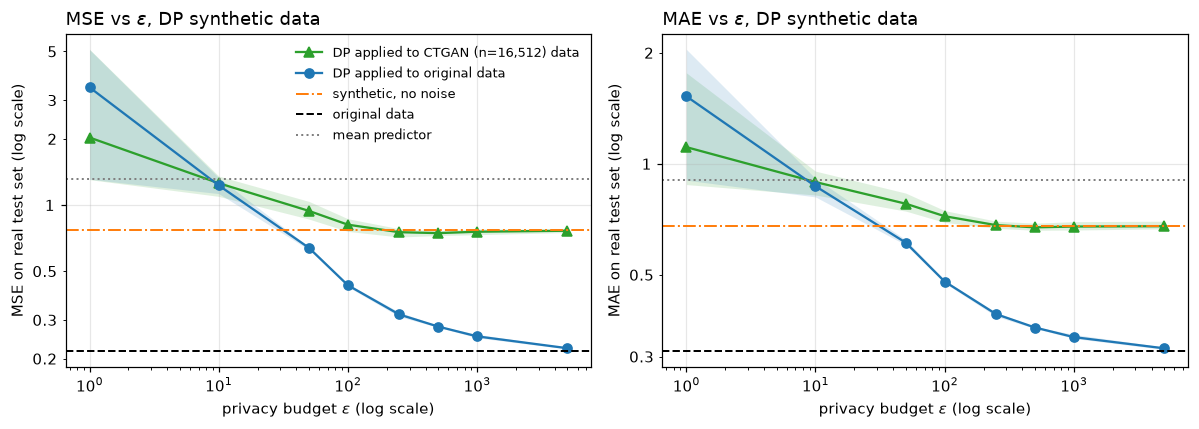

In [22]:
# Figure 4: utility of the DP synthetic datasets (MSE vs epsilon), with DP on the original data for comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MSE", "MAE"]):
    plot_vs_x(ax, dpsyn_results, "epsilon", metric, C_DPSYN, "DP applied to CTGAN (n=16,512) data", marker="^")
    plot_vs_x(ax, dp_results[dp_results["epsilon"].isin(DP_SYN_EPSILONS)], "epsilon", metric, C_DP, "DP applied to original data")
    ax.axhline({"MSE": SYN_FULL_MSE, "MAE": SYN_FULL_MAE}[metric], color=C_SYN, ls="-.", lw=1.3, label="synthetic, no noise")
    reference_lines(ax, metric)
    ax.set_xscale("log"); ax.set_yscale("log"); plain_log_ticks(ax, minor=True)
    ax.set_xlabel(r"privacy budget $\epsilon$ (log scale)"); ax.set_ylabel(f"{metric} on real test set (log scale)")
    ax.set_title(rf"{metric} vs $\epsilon$, DP synthetic data", loc="left")
axes[0].legend(loc="upper right", fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_dp_synthetic_utility.png"); plt.show()

## 8. Summary of all results

In [23]:
summary_rows = [{"dataset": "Original", "parameter": "-", "MSE": ORIG_MSE, "MAE": ORIG_MAE},
                {"dataset": "Mean predictor", "parameter": "-", "MSE": MEAN_MSE, "MAE": MEAN_MAE}]
summary_rows += [{"dataset": "DP (original)", "parameter": f"eps={e:g}", "MSE": dp_summary.loc[e, ("MSE", "mean")],
                  "MAE": dp_summary.loc[e, ("MAE", "mean")]} for e in EPSILONS]
summary_rows += [{"dataset": "Synthetic (CTGAN)", "parameter": f"n={n}", "MSE": syn_summary.loc[n, ("MSE", "mean")],
                  "MAE": syn_summary.loc[n, ("MAE", "mean")]} for n in SAMPLE_SIZES]
summary_rows += [{"dataset": "DP synthetic", "parameter": f"eps={e:g}", "MSE": dpsyn_summary.loc[e, ("MSE", "mean")],
                  "MAE": dpsyn_summary.loc[e, ("MAE", "mean")]} for e in DP_SYN_EPSILONS]
all_summary = pd.DataFrame(summary_rows)
all_summary["MSE / original MSE"] = all_summary["MSE"] / ORIG_MSE
all_summary.to_csv(RES_DIR / "summary_all.csv", index=False)
display(all_summary.round(4))

,dataset,parameter,MSE,MAE,MSE / original MSE
0,Original,-,0.2158,0.3099,1.0000
1,Mean predictor,-,1.3107,0.9061,6.0742
2,DP (original),eps=0.1,218.2849,12.3070,1011.6116
3,DP (original),eps=0.5,3.5517,1.4923,16.4600
4,DP (original),eps=1,3.4316,1.5246,15.9033
5,DP (original),eps=5,1.4052,0.9331,6.5124
6,DP (original),eps=10,1.2290,0.8695,5.6957
7,DP (original),eps=25,0.9754,0.7639,4.5202
8,DP (original),eps=50,0.6384,0.6112,2.9586
9,DP (original),eps=100,0.4316,0.4795,2.0001


### Main findings (discussed in more detail in the report)

- **DP (Laplace).** For $\varepsilon \le 5$ the data is useless: the regressor is no better than just
  predicting the mean (MSE 1.31). The utility slowly comes back between $\varepsilon$ = 10 and 1000. The
  MSE is 2x the original at $\varepsilon = 100$ and 3.4 % above it at $\varepsilon = 5000$.
- **CTGAN.** When trained on 1000 or fewer records the synthetic data has no usable signal (mean MSE
  above the mean predictor). Only the model trained on all 16512 records is clearly useful, with MSE 0.77
  (3.6x the original). The SDV quality score goes from 0.66 to 0.86 with n. No synthetic row is a copy of
  a training record and all DCR ratios are at least 1.
- **Task 5.** The best synthetic dataset has the same utility as DP data at $\varepsilon \approx 38$
  (checked: 0.78 vs 0.77). The n = 5000 datasets match $\varepsilon \approx 9$.
- **Task 6.** Adding noise to the synthetic data increases the MSE by 164 % at $\varepsilon = 1$, 64 % at
  10, 23 % at 50 and 6 % at 100. From $\varepsilon = 250$ there is no measurable change. For
  $\varepsilon \ge 10$, noise on the original data gives better utility than noise on the synthetic data.